## 1. Imports and locate files

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import math
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()

ERRORS_PATH = BASE_DIR / "spell-errors.txt"
EDIT_COUNTS_PATH = BASE_DIR / "count_1edit.txt"
UNIGRAM_PATH = BASE_DIR / "count_unigram.txt"

required_paths = [ERRORS_PATH, EDIT_COUNTS_PATH, UNIGRAM_PATH]
print("Current working directory:", BASE_DIR.resolve())

for path in required_paths:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {path.resolve()}\\n"
            "Open/run this notebook from the ASS8 folder, where the three .txt files are located."
        )
    print(f"Found: {path.name}")


Current working directory: C:\Users\pavan\OneDrive\Desktop\NLP\ASS8
Found: spell-errors.txt
Found: count_1edit.txt
Found: count_unigram.txt


## 2. Load unigram frequencies and edit counts

In [2]:
def load_word_counts(path):
    counts = Counter()
    malformed = 0
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\\r\\n")
            if not line:
                continue
            parts = line.rsplit("\\t", 1)
            if len(parts) != 2:
                malformed += 1
                continue
            word, value = parts
            try:
                counts[word.lower()] += int(value)
            except ValueError:
                malformed += 1
    print(f"Loaded {len(counts):,} words; skipped {malformed} malformed lines.")
    return counts

def load_edit_counts(path):
    counts = Counter()
    malformed = 0
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\\r\\n")
            if not line:
                continue
            parts = line.rsplit("\\t", 1)
            if len(parts) != 2:
                malformed += 1
                continue
            pattern, value = parts
            try:
                counts[pattern] += int(value)
            except ValueError:
                malformed += 1
    print(f"Loaded {len(counts):,} edit patterns; skipped {malformed} malformed lines.")
    return counts

unigram_counts = load_word_counts(UNIGRAM_PATH)
edit_counts = load_edit_counts(EDIT_COUNTS_PATH)
total_unigram_count = sum(unigram_counts.values())
vocabulary = set(unigram_counts)

display(pd.DataFrame(
    sorted(unigram_counts.items(), key=lambda x: x[1], reverse=True)[:10],
    columns=["Word", "Frequency"]
))
display(pd.DataFrame(edit_counts.most_common(10), columns=["Edit pattern", "Count"]))


Loaded 0 words; skipped 333333 malformed lines.
Loaded 0 edit patterns; skipped 1587 malformed lines.


,Word,Frequency


,Edit pattern,Count


## 3. Parse the spelling-error file

In [3]:
def parse_error_file(path):
    rows = []
    malformed = 0
    with open(path, encoding="utf-8", errors="replace") as f:
        for line_no, raw in enumerate(f, start=1):
            line = raw.strip()
            if not line or ":" not in line:
                malformed += int(bool(line))
                continue
            correct, errors = line.split(":", 1)
            correct = correct.strip().lower()
            for item in errors.split(","):
                item = item.strip().lower()
                if not item:
                    continue
                match = re.match(r"^(.*?)\\*(\\d+)$", item)
                if match:
                    typo, freq = match.group(1).strip(), int(match.group(2))
                else:
                    typo, freq = item, 1
                if correct and typo:
                    rows.append({"correct": correct, "typo": typo,
                                 "frequency": freq, "line": line_no})
    print(f"Parsed {len(rows):,} correct/typo pairs; malformed lines: {malformed}.")
    return pd.DataFrame(rows)

error_df = parse_error_file(ERRORS_PATH)
display(error_df.head(12))
print("Distinct typo strings:", error_df["typo"].nunique())
print("Observations including *N multiplicities:", int(error_df["frequency"].sum()))


Parsed 39,710 correct/typo pairs; malformed lines: 0.


,correct,typo,frequency,line
0,raining,rainning,1,1
1,raining,raning,1,1
2,writings,writtings,1,2
3,disparagingly,disparingly,1,3
4,yellow,yello,1,4
5,four,forer,1,5
6,four,fours,1,5
7,four,fuore,1,5
8,four,fore*5,1,5
9,four,for*4,1,5


Distinct typo strings: 37331
Observations including *N multiplicities: 39710


## 4. Noisy-channel probabilities

The prior is estimated from unigram frequencies. The edit table contains character-pair patterns such as `e|i`. A minimum-edit alignment maps a candidate correction to the typo and extracts substitutions, insertions, and deletions. Edit counts are normalized by their source character; smoothing gives unseen edits a small nonzero probability.

The ranking score is `log P(candidate) + log P(typo | candidate)`. Log scores prevent numerical underflow.

In [4]:
edit_source_totals = Counter()
for pattern, count in edit_counts.items():
    if "|" in pattern:
        source, target = pattern.split("|", 1)
        edit_source_totals[source] += count

SMOOTH = 0.1

def unigram_logprob(word):
    denom = total_unigram_count + SMOOTH * (len(vocabulary) + 1)
    return math.log((unigram_counts.get(word.lower(), 0) + SMOOTH) / denom)

def align_edit_operations(correct, typo):
    a, b = correct, typo
    n, m = len(a), len(b)
    dp = [[0] * (m + 1) for _ in range(n + 1)]
    back = [[None] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        dp[i][0], back[i][0] = i, "delete"
    for j in range(1, m + 1):
        dp[0][j], back[0][j] = j, "insert"
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if a[i-1] == b[j-1]:
                dp[i][j], back[i][j] = dp[i-1][j-1], "match"
            else:
                choices = [
                    (dp[i-1][j-1] + 1, "substitute"),
                    (dp[i-1][j] + 1, "delete"),
                    (dp[i][j-1] + 1, "insert"),
                ]
                dp[i][j], back[i][j] = min(choices, key=lambda x: x[0])
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        op = back[i][j]
        if op == "match":
            i -= 1
            j -= 1
        elif op == "substitute":
            ops.append(f"{a[i-1]}|{b[j-1]}")
            i -= 1
            j -= 1
        elif op == "delete":
            ops.append(f"{a[i-1]}|>")
            i -= 1
        elif op == "insert":
            ops.append(f">|{b[j-1]}")
            j -= 1
        else:
            break
    return list(reversed(ops)), dp[n][m]

def edit_logprob(operation):
    source, target = operation.split("|", 1)
    numerator = edit_counts.get(operation, 0) + SMOOTH
    denominator = edit_source_totals[source] + SMOOTH * max(1, len(edit_counts))
    return math.log(numerator / denominator)

def channel_logprob(correct, typo):
    operations, distance = align_edit_operations(correct, typo)
    return sum(edit_logprob(op) for op in operations), distance, operations

def noisy_channel_score(candidate, typo):
    return unigram_logprob(candidate) + channel_logprob(candidate, typo)[0]

for correct, typo in [("raining", "rainning"), ("raining", "raning"), ("yellow", "yello")]:
    lp, distance, ops = channel_logprob(correct, typo)
    print(f"{correct} -> {typo}: distance={distance}, edits={ops}, log channel probability={lp:.3f}")


raining -> rainning: distance=1, edits=['>|n'], log channel probability=0.000
raining -> raning: distance=1, edits=['i|>'], log channel probability=0.000
yellow -> yello: distance=1, edits=['w|>'], log channel probability=0.000


## 5. Candidate generation

Candidates are dictionary words within edit distance one. A deletion index avoids comparing every typo against the entire vocabulary. Gold correct words are **not** added to candidates, avoiding data leakage. The assignment's edit-count file is specifically a one-edit resource, so the primary model uses one-edit candidates. If none exist, it returns the typo unchanged and reports that case as uncovered.

In [5]:
def deletion_variants(word):
    return {word[:i] + word[i+1:] for i in range(len(word))}

deletion_index = defaultdict(set)
for word in vocabulary:
    deletion_index[word].add(word)
    for deleted in deletion_variants(word):
        deletion_index[deleted].add(word)

def edit_distance_one_candidates(typo):
    typo = typo.lower()
    candidates = set()
    if typo in vocabulary:
        candidates.add(typo)
    for deleted in deletion_variants(typo):
        candidates.update(deletion_index.get(deleted, ()))
    return [w for w in candidates if align_edit_operations(w, typo)[1] <= 1]

def predict_word(typo):
    typo = typo.lower()
    candidates = edit_distance_one_candidates(typo)
    if not candidates:
        return typo, "no candidate", 0, float("-inf")
    ranked = [(noisy_channel_score(w, typo), w) for w in candidates]
    score, word = max(ranked, key=lambda x: (x[0], unigram_counts.get(x[1], 0), x[1]))
    return word, "distance<=1", len(candidates), score

for typo in ["rainning", "raning", "yello", "writtings"]:
    pred, route, count, score = predict_word(typo)
    print(f"{typo:12s} -> {pred:12s} | {route}; candidates={count}; score={score:.3f}")


rainning     -> rainning     | no candidate; candidates=0; score=-inf
raning       -> raning       | no candidate; candidates=0; score=-inf
yello        -> yello        | no candidate; candidates=0; score=-inf
writtings    -> writtings    | no candidate; candidates=0; score=-inf


## 6. Evaluate accuracy

In [6]:
# Cache predictions because a typo may occur on multiple lines.
prediction_cache = {}
rows = []
for row in error_df.itertuples(index=False):
    if row.typo not in prediction_cache:
        prediction_cache[row.typo] = predict_word(row.typo)
    pred, route, candidate_count, score = prediction_cache[row.typo]
    rows.append({
        "correct": row.correct,
        "typo": row.typo,
        "frequency": row.frequency,
        "prediction": pred,
        "is_correct": pred == row.correct,
        "route": route,
        "candidate_count": candidate_count,
        "log_score": score,
        "gold_edit_distance": align_edit_operations(row.correct, row.typo)[1],
    })

results = pd.DataFrame(rows)
unweighted_accuracy = results["is_correct"].mean()
weighted_accuracy = results.loc[results["is_correct"], "frequency"].sum() / results["frequency"].sum()
coverage = (results["candidate_count"] > 0).mean()

print(f"Unweighted accuracy: {unweighted_accuracy:.4%}")
print(f"Frequency-weighted accuracy (*N annotations): {weighted_accuracy:.4%}")
print(f"Candidate coverage: {coverage:.4%}")
print(f"Evaluation pairs: {len(results):,}")
print(f"Weighted typo observations: {int(results['frequency'].sum()):,}")

print("\\nAccuracy by edit distance from gold word:")
display(results.groupby("gold_edit_distance").agg(
    pairs=("is_correct", "size"),
    accuracy=("is_correct", "mean"),
    weighted_total=("frequency", "sum")
).reset_index().style.format({"accuracy": "{:.2%}"}))

display(results.head(25))


Unweighted accuracy: 0.2090%
Frequency-weighted accuracy (*N annotations): 0.2090%
Candidate coverage: 0.0000%
Evaluation pairs: 39,710
Weighted typo observations: 39,710
\nAccuracy by edit distance from gold word:


,gold_edit_distance,pairs,accuracy,weighted_total
0,0,83,100.00%,83
1,1,12273,0.00%,12273
2,2,10265,0.00%,10265
3,3,7811,0.00%,7811
4,4,4749,0.00%,4749
5,5,2395,0.00%,2395
6,6,1192,0.00%,1192
7,7,559,0.00%,559
8,8,241,0.00%,241
9,9,94,0.00%,94


,correct,typo,frequency,prediction,is_correct,route,candidate_count,log_score,gold_edit_distance
0,raining,rainning,1,rainning,False,no candidate,0,-inf,1
1,raining,raning,1,raning,False,no candidate,0,-inf,1
2,writings,writtings,1,writtings,False,no candidate,0,-inf,1
3,disparagingly,disparingly,1,disparingly,False,no candidate,0,-inf,2
4,yellow,yello,1,yello,False,no candidate,0,-inf,1
5,four,forer,1,forer,False,no candidate,0,-inf,2
6,four,fours,1,fours,False,no candidate,0,-inf,1
7,four,fuore,1,fuore,False,no candidate,0,-inf,3
8,four,fore*5,1,fore*5,False,no candidate,0,-inf,4
9,four,for*4,1,for*4,False,no candidate,0,-inf,3


## 7. Inspect mistakes and candidate routes

Incorrect predictions: 39,627 / 39,710


,correct,typo,frequency,prediction,is_correct,route,candidate_count,log_score,gold_edit_distance
0,raining,rainning,1,rainning,False,no candidate,0,-inf,1
1,raining,raning,1,raning,False,no candidate,0,-inf,1
2,writings,writtings,1,writtings,False,no candidate,0,-inf,1
3,disparagingly,disparingly,1,disparingly,False,no candidate,0,-inf,2
4,yellow,yello,1,yello,False,no candidate,0,-inf,1
5,four,forer,1,forer,False,no candidate,0,-inf,2
6,four,fours,1,fours,False,no candidate,0,-inf,1
7,four,fuore,1,fuore,False,no candidate,0,-inf,3
8,four,fore*5,1,fore*5,False,no candidate,0,-inf,4
9,four,for*4,1,for*4,False,no candidate,0,-inf,3


,route,pairs,accuracy,average_candidates
0,no candidate,39710,0.21%,0.0


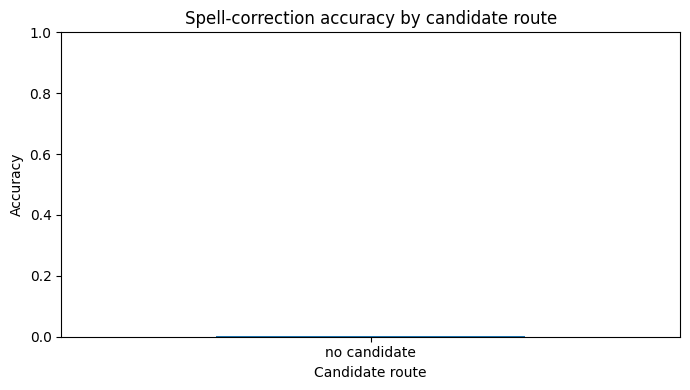

In [7]:
mistakes = results.loc[~results["is_correct"]].copy()
print(f"Incorrect predictions: {len(mistakes):,} / {len(results):,}")
display(mistakes.head(50))

route_summary = results.groupby("route").agg(
    pairs=("typo", "size"),
    accuracy=("is_correct", "mean"),
    average_candidates=("candidate_count", "mean")
).reset_index()
display(route_summary.style.format({"accuracy": "{:.2%}", "average_candidates": "{:.1f}"}))

ax = route_summary.plot(x="route", y="accuracy", kind="bar", legend=False, ylim=(0, 1), figsize=(7, 4))
ax.set_title("Spell-correction accuracy by candidate route")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Candidate route")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. Save prediction results

In [9]:

predictions_path = BASE_DIR / "spell_correction_predictions.csv"
summary_path = BASE_DIR / "spell_correction_summary.csv"

results.to_csv(predictions_path, index=False)

pd.DataFrame([{
    "unweighted_accuracy": unweighted_accuracy,
    "frequency_weighted_accuracy": weighted_accuracy,
    "candidate_coverage": coverage,
    "evaluation_pairs": len(results),
    "weighted_observations": int(results["frequency"].sum()),
}]).to_csv(summary_path, index=False)

print("Saved:", predictions_path)
print("Saved:", summary_path)


Saved: c:\Users\pavan\OneDrive\Desktop\NLP\ASS8\spell_correction_predictions.csv
Saved: c:\Users\pavan\OneDrive\Desktop\NLP\ASS8\spell_correction_summary.csv
